# Trend smoothing and cutoff comparison: opening inference strategy

Compare **5-event EWMA, 5-event simple rolling mean, 10-event EWMA, and 10-event simple rolling mean**, each at **+/-0.02 and +/-0.03**. Source: opening inference strategy, training-only model for validation and train+validation-refitted model for test. Use saved original opening strategy returns and parameters, without rerunning a parameter search.

Hold the underlying Brier advantage window at **100 fights** and the slope-fitting window at **five smoothed event points** for all eight scenarios. EWMA uses `adjust=False`; simple means require a complete window. Normalize each smoothing configuration's slope by its own smoothed-series standard deviation over the original training period. Thus cutoff units are training SD per event. Classify using the previous event's slope, then exclude current flat events from metrics and betting. Different configurations can retain different numbers of events. The five-year mean groups use the unsmoothed event-end 100-fight advantage and remain independent of smoothing.

For every scenario report: (1) flat exclusion alone, (2) prior-Brier reductions, (3) volatility only, (4) combined reduction-only filters. **Fixed above-mean volatility target:** last 10 completed above-mean non-flat events; denominator: last 10 events in current mean group including flats. **Prior-Brier reductions:** previous single-event actual Vegas Brier predicts return via expanding nonnegative ridge, penalty 10, after 20 retained observations. Original returns update all estimation histories; prior-only date checks remain in place. No scaler increases original exposure.

Retune no parameters: this is an eight-setting descriptive sensitivity comparison on previously examined data. Historical in-sample fighter probabilities, strategy selection, and test-model refit remain limitations. Growth is per retained event, volatility in percentage points. Calendar-aligned wealth plots assign zero return to skipped events; reported return averages exclude those events. Results with different event counts should be compared using both event metrics and the wealth paths. The original EWMA-5/+/-0.03 combined result is checked against rolling_brier.ipynb.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/ufc_betting').is_dir())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from ufc_betting.config import settings
WINDOW_FIGHTS=100
FLAT_BAND=.02
SMOOTH_SPAN=5
SMOOTH_METHOD="EWMA"
SLOPE_EVENTS=5
VOL_EVENTS=10
BRIER_MIN_EVENTS=20
BRIER_RIDGE=10.
PREDICTIONS=settings.data_dir/'model_comparisons/lr_open_close/report_predictions'
BACKTESTS=settings.data_dir/'backtest_results/model_comparisons/inference_market_models'
KEYS=['date','fighter_red','fighter_blue']

def score_fights(frame,market):
    frame=frame.copy();frame['date']=pd.to_datetime(frame.date).dt.normalize()
    p=pd.to_numeric(frame.proba_red,errors='coerce')
    r=pd.to_numeric(frame[f'dec_{market}_red'],errors='coerce');b=pd.to_numeric(frame[f'dec_{market}_blue'],errors='coerce')
    valid=frame.winner.isin([0,1])&p.between(0,1)&np.isfinite(r)&np.isfinite(b)&r.gt(1)&b.gt(1)
    q=(1/r)/(1/r+1/b)
    frame=frame.loc[valid].copy()
    frame['vegas_actual']=(q.loc[valid]-frame.winner)**2
    frame['vegas_expected']=q.loc[valid]*(1-q.loc[valid])
    frame['model_brier']=(p.loc[valid]-frame.winner)**2
    frame['excess']=frame.vegas_actual-frame.vegas_expected
    frame['advantage']=frame.vegas_actual-frame.model_brier
    return frame.sort_values('date',kind='stable').reset_index(drop=True)

def metrics(returns):
    r=np.asarray(returns,float)/100
    assert np.isfinite(r).all() and (r>-1).all()
    wealth=np.r_[1.,np.cumprod(1+r)]
    return dict(events=len(r),geometric_growth_pct=100*np.expm1(np.log1p(r).mean()),
        average_return_pct=100*r.mean(),volatility_pp=100*r.std(ddof=1),
        worst_event_pct=100*r.min(),max_drawdown_pct=-100*(wealth/np.maximum.accumulate(wealth)-1).min(),
        final_wealth=wealth[-1])

# Opening notebook's event gate is independent of the closing-trend diagnostics.
OPENING_FLAT_BAND = .03

def opening_event_filter():
    rows=[]
    train_end=pd.to_datetime(pd.read_csv(PREDICTIONS/'train/open/inference/train_with_open.csv').date).max()
    for label,fit,split,prefix in [('Validation','train','val','train_val'),('Test','trainval','test','trainval_test')]:
        root=PREDICTIONS/fit/'open/inference'
        warm=score_fights(pd.read_csv(root/'train_with_open.csv'),'open')
        pred=pd.read_csv(root/f'{split}_with_open.csv',parse_dates=['date'])
        saved=pd.read_csv(BACKTESTS/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
        current=score_fights(saved[KEYS].merge(pred,on=KEYS,validate='one_to_one',sort=False),'open')
        history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable')
        history['rolling']=history.advantage.rolling(WINDOW_FIGHTS,min_periods=WINDOW_FIGHTS).mean()
        ends=history.groupby('date')['rolling'].last().dropna()
        smoothed=(ends.ewm(span=SMOOTH_SPAN,adjust=False).mean() if SMOOTH_METHOD=='EWMA' else ends.rolling(SMOOTH_SPAN,min_periods=SMOOTH_SPAN).mean())
        t=np.arange(SLOPE_EVENTS,dtype=float);t-=t.mean()
        slopes=smoothed.rolling(SLOPE_EVENTS).apply(lambda v:np.dot(t,v)/np.dot(t,t),raw=True)
        sd=smoothed.loc[smoothed.index<=train_end].std(ddof=1)
        dates=pd.DatetimeIndex(sorted(saved.date.unique()))
        part=pd.DataFrame({'opening_prior_slope':slopes.shift(1).reindex(dates)/sd,
            'opening_source_date':pd.Series(ends.index,index=ends.index).shift(1).reindex(dates)})
        assert part.notna().all().all() and (part.opening_source_date<part.index).all()
        part['opening_keep']=part.opening_prior_slope.abs().gt(OPENING_FLAT_BAND)
        rows.append(part)
    result=pd.concat(rows).sort_index()
    assert result.index.is_unique and result.opening_keep.any()
    return result

OPENING_EVENT_FILTER=opening_event_filter()

def analyze_closing(market):
    band=OPENING_FLAT_BAND if market=='open' else FLAT_BAND
    histories={};parts=[]
    train_end=pd.to_datetime(pd.read_csv(PREDICTIONS/'train/open/inference/train_with_open.csv').date).max()
    for label,fit,split,prefix in [('Validation','train','val','train_val'),('Test','trainval','test','trainval_test')]:
        root=PREDICTIONS/fit/'open/inference'
        pred=pd.read_csv(root/f'{split}_with_{market}.csv',parse_dates=['date'])
        warm=score_fights(pd.read_csv(root/f'train_with_{market}.csv'),market)
        saved=pd.read_csv(BACKTESTS/f'{prefix}_open_with_{market}_inference_{"no_decay" if market=="open" else "decay"}_moneylines.csv',parse_dates=['date'])
        assert pred.probability_model.eq('inference').all()
        saved['date']=saved.date.dt.normalize();pred['date']=pred.date.dt.normalize()
        check=saved.merge(pred[KEYS+['proba_red']],on=KEYS,how='outer',validate='one_to_one',indicator=True,suffixes=('','_reference'))
        assert check['_merge'].eq('both').all()
        saved_p=check.proba_red if 'proba_red' in saved else check.choice_proba.where(check.pred_winner.eq(1),1-check.choice_proba)
        reference=check.proba_red_reference if 'proba_red' in saved else check.proba_red
        np.testing.assert_allclose(saved_p,reference,atol=1e-10)
        current=score_fights(saved[KEYS].merge(pred,on=KEYS,validate='one_to_one',sort=False),market)
        assert warm.date.max()<current.date.min()
        history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable').reset_index(drop=True)
        for col in ['vegas_actual','vegas_expected','excess','advantage']:
            history['rolling_'+col]=history[col].rolling(WINDOW_FIGHTS,min_periods=WINDOW_FIGHTS).mean()
        histories[label]=history
        endpoints=history.groupby('date').rolling_advantage.last().dropna()
        event_brier=history.groupby('date').vegas_actual.mean()
        smooth=(endpoints.ewm(span=SMOOTH_SPAN,adjust=False).mean() if SMOOTH_METHOD=='EWMA' else endpoints.rolling(SMOOTH_SPAN,min_periods=SMOOTH_SPAN).mean())
        t=np.arange(SLOPE_EVENTS,dtype=float);t-=t.mean()
        slope=smooth.rolling(SLOPE_EVENTS).apply(lambda v:np.dot(t,v)/np.dot(t,t),raw=True)
        sd=smooth.loc[smooth.index<=train_end].std(ddof=1);assert sd>0
        cols=['bankroll_postevent','event_payout_money_line','parlay_net','event_total_fstar']
        assert saved.groupby('date')[cols].nunique(dropna=False).le(1).all().all()
        event=saved.groupby('date')[cols].first().sort_index()
        profit=event.event_payout_money_line+event.parlay_net
        start=event.bankroll_postevent-profit
        assert start.gt(0).all()
        np.testing.assert_allclose(start.iloc[1:],event.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
        part=pd.DataFrame(index=event.index)
        part['return_pct']=100*profit/start
        part['stake_fraction']=event.event_total_fstar
        assert part.stake_fraction.between(0,1+1e-10).all()
        part['prior_advantage']=endpoints.shift(1).reindex(part.index)
        part['prior_brier']=event_brier.shift(1).reindex(part.index)
        part['slope']=slope.shift(1).reindex(part.index)/sd
        part['source_date']=pd.Series(endpoints.index,index=endpoints.index).shift(1).reindex(part.index)
        part['five_year_mean']=[endpoints.loc[(endpoints.index>=date-pd.DateOffset(years=5))&(endpoints.index<date)].mean() for date in part.index]
        part['regime']=np.where(part.prior_advantage>part.five_year_mean,'Above mean','At/below mean')
        part['trend']=np.select([part.slope>band,part.slope < -band],['Uptrend','Downtrend'],default='Flat')
        part['split']=label
        assert part.notna().all().all() and (part.source_date<part.index).all()
        parts.append(part)
    all_events=pd.concat(parts).sort_index()
    assert all_events.index.is_unique
    all_events=all_events.join(OPENING_EVENT_FILTER,validate='one_to_one')
    assert all_events.opening_keep.notna().all()
    active=all_events.loc[all_events.opening_keep].copy()
    assert active.index.equals(OPENING_EVENT_FILTER.index[OPENING_EVENT_FILTER.opening_keep])
    decisions=[]
    for j,(date,row) in enumerate(active.iterrows()):
        past=all_events.loc[all_events.index<date]
        target=past.loc[past.regime.eq('Above mean') & past.trend.ne('Flat')].tail(VOL_EVENTS)
        own=past.loc[past.regime.eq(row.regime)].tail(VOL_EVENTS)
        vol=1.
        if len(target)==VOL_EVENTS and len(own)==VOL_EVENTS:
            denom=own.return_pct.std(ddof=1)
            vol=min(1.,target.return_pct.std(ddof=1)/denom) if denom>1e-12 else 1.
        training=active.iloc[:j];brier=1.;prediction=baseline=np.nan
        if len(training)>=BRIER_MIN_EVENTS:
            x=training.prior_brier.to_numpy();y=training.return_pct.to_numpy()
            baseline=y.mean();prediction=baseline
            if x.std()>1e-12:
                z=(x-x.mean())/x.std()
                coef=max(0.,np.dot(z,y-baseline)/(np.dot(z,z)+BRIER_RIDGE))
                prediction=baseline+coef*(row.prior_brier-x.mean())/x.std()
            brier=float(np.clip(prediction/baseline,0,1)) if baseline>1e-12 else float(prediction>0)
        decisions.append(dict(date=date,vol_multiplier=vol,brier_multiplier=brier,combined_multiplier=vol*brier,
            predicted_return_pct=prediction,baseline_return_pct=baseline))
    active=active.join(pd.DataFrame(decisions).set_index('date'))
    local_scalers=active[['vol_multiplier','brier_multiplier','combined_multiplier']].copy()
    if market != 'open':
        # Transfer the exact opening multipliers by event date; never fit them to closing returns.
        opening=OPENING_SCALERS.reindex(active.index)
        assert opening.notna().all().all()
        pd.testing.assert_index_equal(active.index,OPENING_SCALERS.index)
        for column in ['vol_multiplier','brier_multiplier','combined_multiplier']:
            active[column]=opening[column]
        assert active.combined_multiplier.le(active.vol_multiplier*active.brier_multiplier+1e-12).all()

    for variant,factor in [('Volatility only','vol_multiplier'),('Prior-Brier reductions','brier_multiplier'),('Combined','combined_multiplier')]:
        assert active[factor].between(0,1).all()
        assert (active[factor]*active.stake_fraction<=1+1e-10).all()
        active[variant]=active.return_pct*active[factor]
    active['Original']=active.return_pct
    records=[]
    for split,part in [('Combined period',active),*list(active.groupby('split',sort=False))]:
        for variant in ['Original','Prior-Brier reductions','Volatility only','Combined']:
            records.append(dict(market=market,split=split,strategy=variant,**metrics(part[variant])))
    summary=pd.DataFrame(records)
    # Stage-consistent timeline: training/validation use train fit; test uses trainval refit.
    plot_train=histories['Validation'].copy();plot_train['split']=np.where(plot_train.date<=train_end,'Train','Validation')
    plot_test=histories['Test'].loc[histories['Test'].date.isin(parts[1].index)].copy();plot_test['split']='Test'
    plotted=pd.concat([plot_train,plot_test],ignore_index=True)
    fig,axes=plt.subplots(3,1,figsize=(15,12),sharex=True,constrained_layout=True)
    for stage,part in plotted.groupby('split',sort=False):
        for col,label,color in [('rolling_vegas_actual','Actual Vegas Brier','tab:blue'),('rolling_vegas_expected','Expected Vegas Brier: p(1-p)','tab:orange')]:
            axes[0].plot(part.date,part[col],color=color,label=label if stage=='Train' else None)
        axes[1].plot(part.date,part.rolling_excess,color='tab:purple')
        axes[2].plot(part.date,part.rolling_advantage,label=stage)
    axes[0].set(title=f'{market}: actual versus expected Vegas Brier (100 fights)',ylabel='Brier score');axes[0].legend()
    axes[1].set(title='Actual minus expected Vegas Brier (100 fights)',ylabel='Excess Brier')
    axes[2].set(title='Rolling Brier advantage (100 fights)',ylabel='Vegas Brier minus model Brier',xlabel='Event date');axes[2].legend()
    for ax in axes:
        ax.axvline(parts[0].index.min(),color='gray',ls='--');ax.axvline(parts[1].index.min(),color='black',ls=':');ax.grid(alpha=.2)
    axes[1].axhline(0,color='gray',lw=.7);axes[2].axhline(0,color='gray',lw=.7)
    plt.show()
    fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
    for variant in ['Original','Prior-Brier reductions','Volatility only','Combined']:
        axes[0].plot(active.index,(1+active[variant]/100).cumprod(),label=variant)
        axes[1].plot(active.index,active[variant],label=variant,alpha=.65)
    axes[0].set_yscale('log');axes[0].set(title=f'{market}: linked wealth, opening event filter and opening stake multipliers',ylabel='Wealth from 1 unit');axes[0].legend()
    axes[1].set(title='Event percent returns',ylabel='Return (%)',xlabel='Event date');axes[1].legend()
    for ax in axes:ax.axvline(parts[1].index.min(),color='black',ls=':');ax.grid(alpha=.2)
    plt.show()
    print(f'{market}: {len(all_events)} events, {len(active)} retained by opening filter; {int((all_events.opening_keep & all_events.trend.eq("Flat")).sum())} closing-flat events restored; {int((~all_events.opening_keep & all_events.trend.ne("Flat")).sum())} closing-non-flat events excluded.')
    print(summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
    return dict(events=all_events,filtered=active,metrics=summary,histories=histories,local_scalers=local_scalers)



import contextlib
import io


In [2]:
smoothing_results={}
smoothing_metric_rows=[]
smoothing_count_rows=[]
_saved_show=plt.show
try:
    plt.show=lambda:plt.close('all')
    for method in ['EWMA','Rolling mean']:
        for window in [5,10]:
            for cutoff in [.02,.03]:
                SMOOTH_METHOD=method;SMOOTH_SPAN=window
                OPENING_FLAT_BAND=cutoff;FLAT_BAND=cutoff
                OPENING_EVENT_FILTER=opening_event_filter()
                with contextlib.redirect_stdout(io.StringIO()):
                    result=analyze_closing('open')
                key=(method,window,cutoff);smoothing_results[key]=result
                event=result['events'];active=result['filtered']
                assert active.opening_prior_slope.abs().gt(cutoff).all()
                assert (active.source_date<active.index).all()
                smoothing_count_rows.append(dict(smoothing=method,window=window,cutoff=cutoff,
                    total_events=len(event),retained_events=len(active),excluded_flat=len(event)-len(active),
                    uptrend_events=int(active.trend.eq('Uptrend').sum()),downtrend_events=int(active.trend.eq('Downtrend').sum())))
                for period,part in [('Combined',active),*list(active.groupby('split',sort=False))]:
                    for strategy in ['Original','Prior-Brier reductions','Volatility only','Combined']:
                        smoothing_metric_rows.append(dict(smoothing=method,window=window,cutoff=cutoff,period=period,
                            strategy='Flat filter only' if strategy=='Original' else strategy,**metrics(part[strategy])))
finally:
    plt.show=_saved_show
smoothing_counts=pd.DataFrame(smoothing_count_rows)
smoothing_metrics=pd.DataFrame(smoothing_metric_rows)
raw_events=next(iter(smoothing_results.values()))['events']
raw_metrics=metrics(raw_events.return_pct)
print('EVENT COUNTS:');print(smoothing_counts.to_string(index=False))
print('\nUNFILTERED BASELINE (all 105 events):');print(pd.Series(raw_metrics).to_string())
print('\nCOMBINED VALIDATION + TEST RESULTS:')
print(smoothing_metrics.loc[smoothing_metrics.period.eq('Combined')].to_string(index=False,float_format=lambda x:f'{x:.4f}'))
# Existing default must reproduce the opening notebook's combined reduction-only result.
reference=smoothing_metrics.loc[(smoothing_metrics.smoothing=='EWMA')&(smoothing_metrics.window==5)&
    (smoothing_metrics.cutoff==.03)&(smoothing_metrics.period=='Combined')&(smoothing_metrics.strategy=='Combined')].iloc[0]
np.testing.assert_allclose(reference.geometric_growth_pct,10.8467,atol=.0001)
np.testing.assert_allclose(reference.max_drawdown_pct,58.5257,atol=.0001)


EVENT COUNTS:
   smoothing  window  cutoff  total_events  retained_events  excluded_flat  uptrend_events  downtrend_events
        EWMA       5    0.02           105               92             13              42                50
        EWMA       5    0.03           105               86             19              38                48
        EWMA      10    0.02           105               91             14              38                53
        EWMA      10    0.03           105               85             20              36                49
Rolling mean       5    0.02           105               96              9              47                49
Rolling mean       5    0.03           105               89             16              41                48
Rolling mean      10    0.02           105               98              7              42                56
Rolling mean      10    0.03           105               92             13              40                52

UNFI

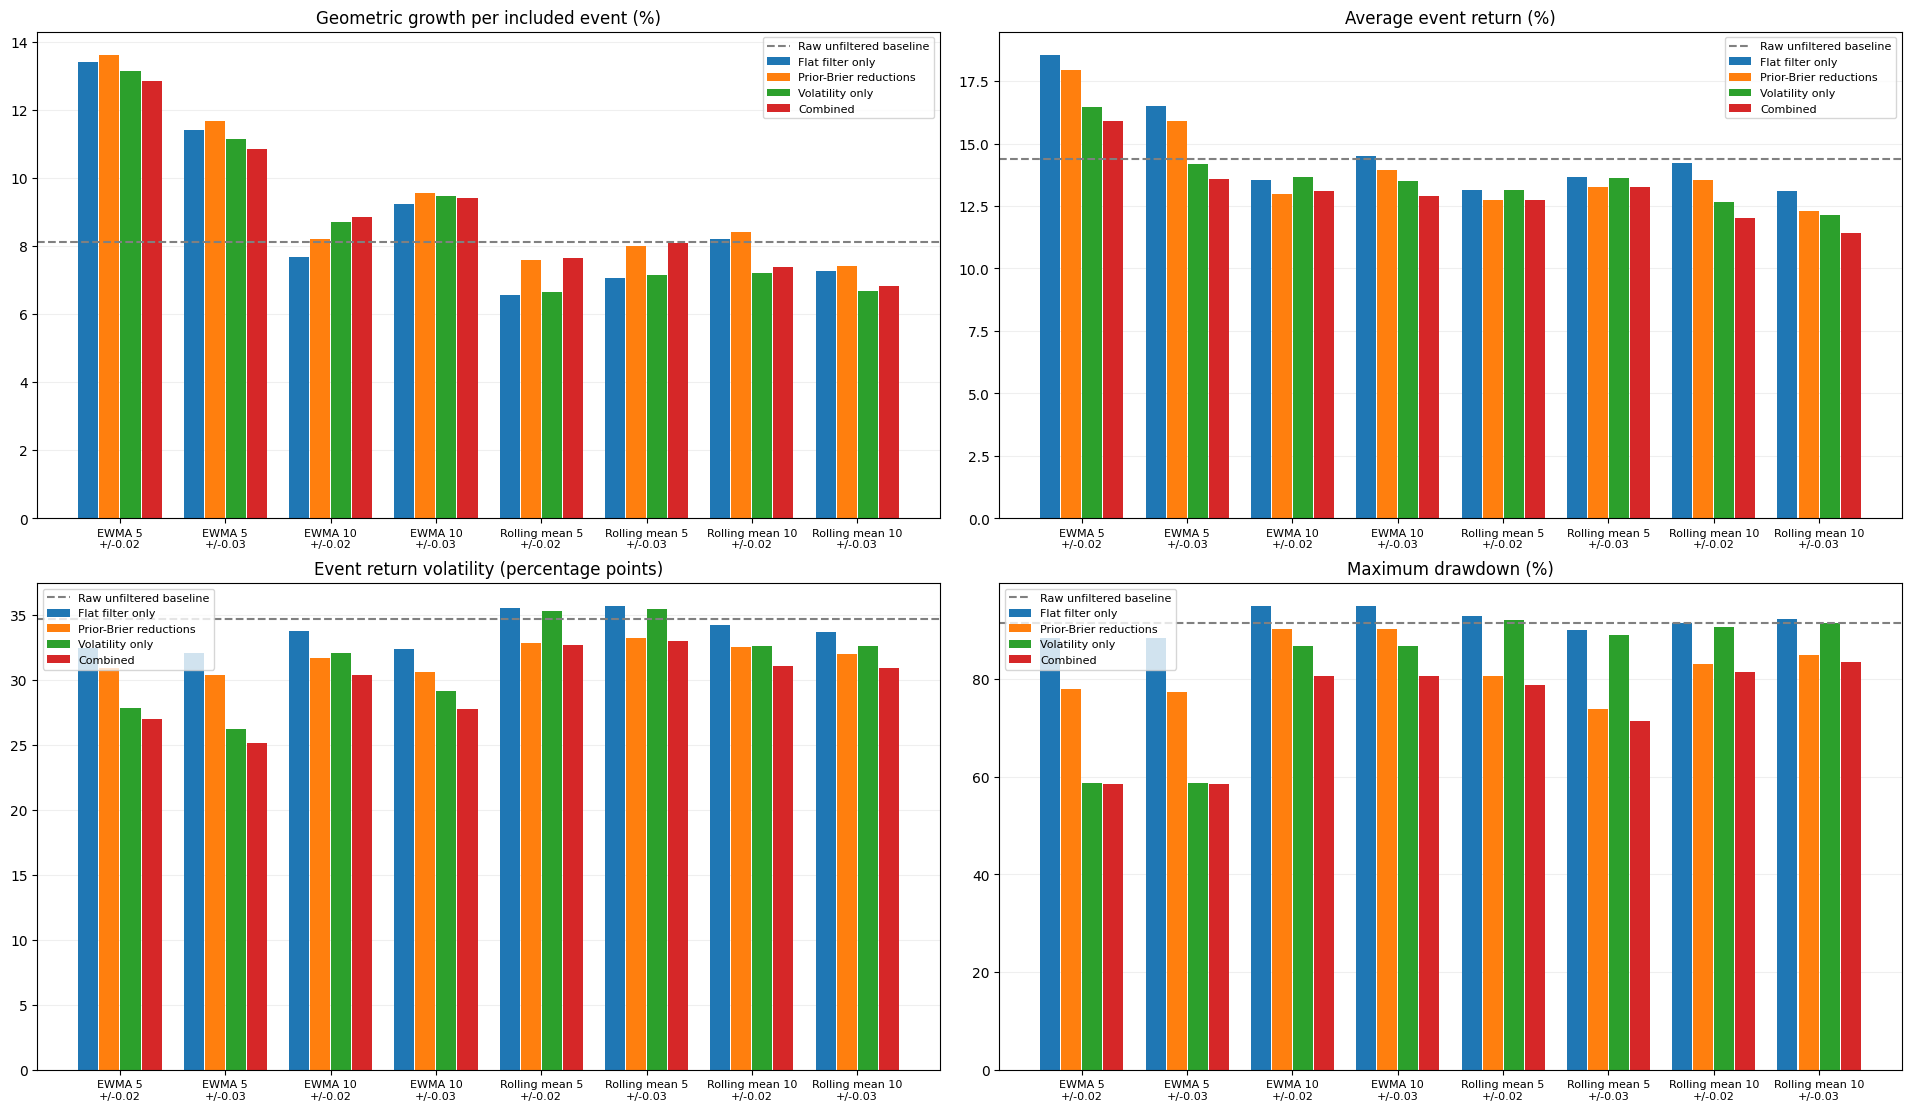

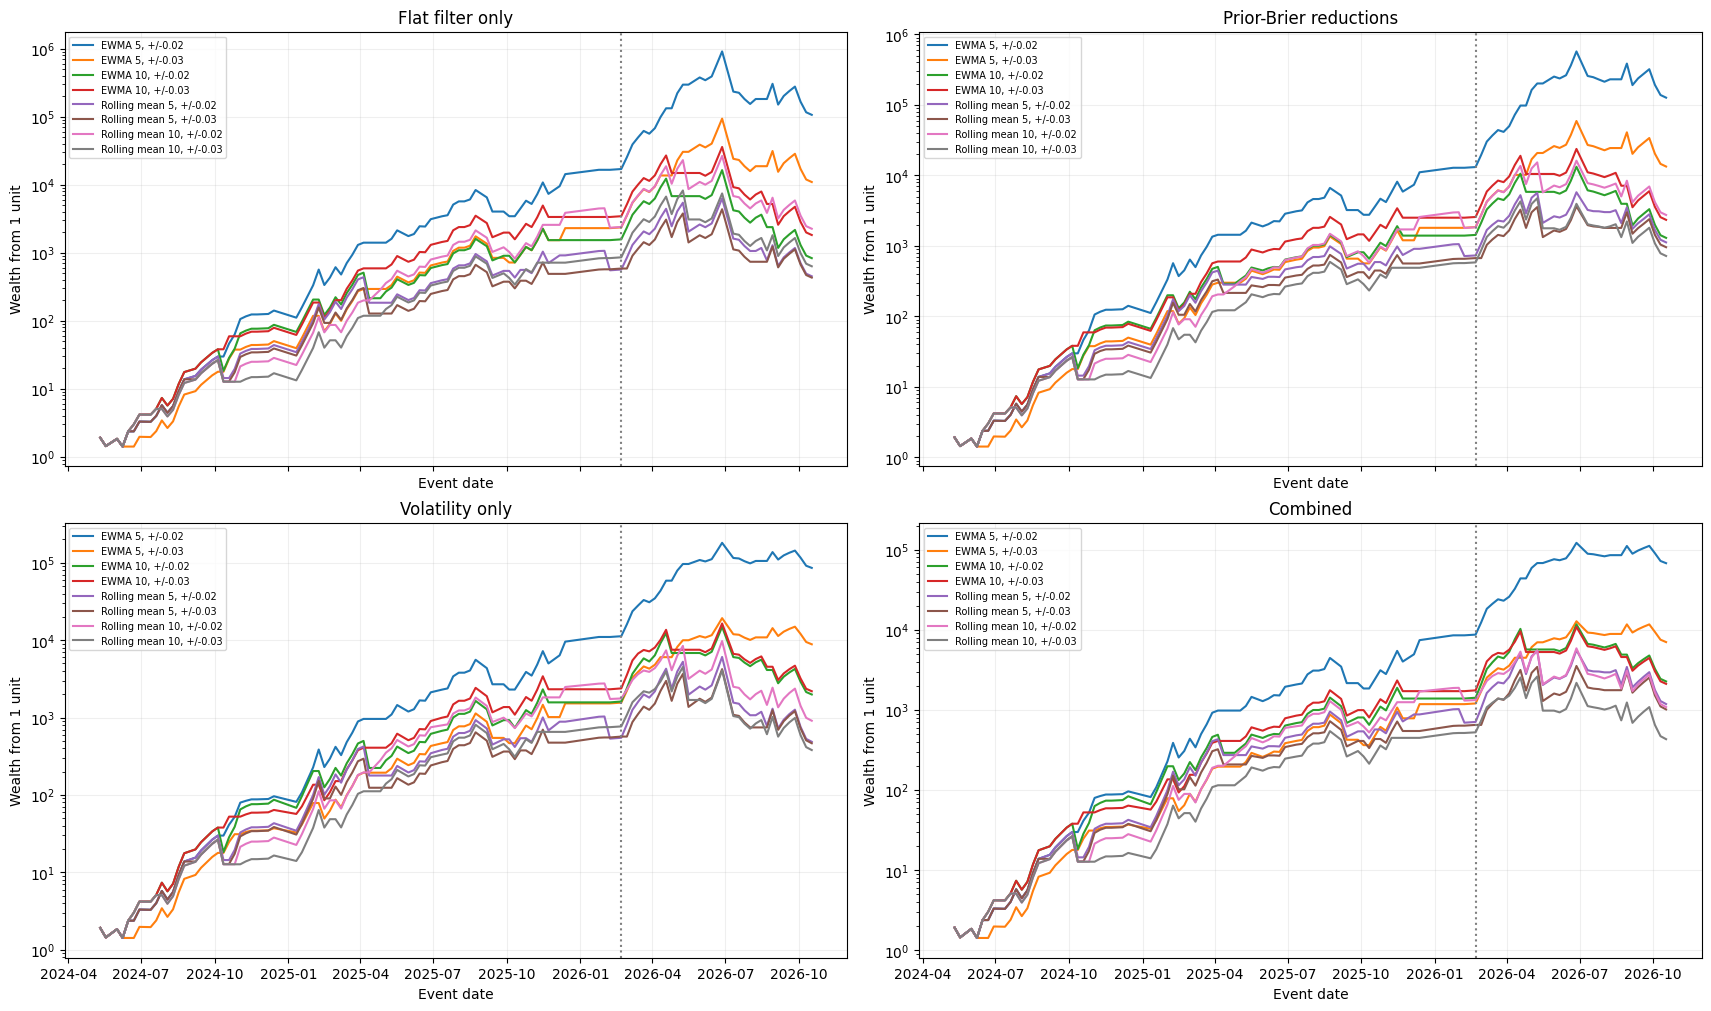

Validation/test metrics are available in smoothing_metrics (period column).


In [3]:
scenario_keys=list(smoothing_results)
scenario_labels=[f'{method} {window}\n+/-{cutoff:.2f}' for method,window,cutoff in scenario_keys]
strategies=['Flat filter only','Prior-Brier reductions','Volatility only','Combined']
fig,axes=plt.subplots(2,2,figsize=(19,11),constrained_layout=True)
for ax,column,title in zip(axes.flat,['geometric_growth_pct','average_return_pct','volatility_pp','max_drawdown_pct'],
        ['Geometric growth per included event (%)','Average event return (%)','Event return volatility (percentage points)','Maximum drawdown (%)']):
    for offset,strategy in zip([-.3,-.1,.1,.3],strategies):
        values=[]
        for method,window,cutoff in scenario_keys:
            row=smoothing_metrics.loc[(smoothing_metrics.smoothing==method)&(smoothing_metrics.window==window)&
                (smoothing_metrics.cutoff==cutoff)&(smoothing_metrics.period=='Combined')&(smoothing_metrics.strategy==strategy)].iloc[0]
            values.append(row[column])
        ax.bar(np.arange(8)+offset,values,width=.19,label=strategy)
    ax.axhline(raw_metrics[column],color='gray',ls='--',label='Raw unfiltered baseline')
    ax.set_xticks(np.arange(8),scenario_labels,fontsize=8);ax.set(title=title);ax.legend(fontsize=8)
    ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
plt.show()
fig,axes=plt.subplots(2,2,figsize=(17,10),sharex=True,constrained_layout=True)
for ax,strategy in zip(axes.flat,strategies):
    for key,result in smoothing_results.items():
        method,window,cutoff=key
        # Skipped flat events have zero return for calendar-aligned wealth only.
        col='Original' if strategy=='Flat filter only' else strategy
        r=result['filtered'][col].reindex(raw_events.index,fill_value=0)
        ax.plot(r.index,(1+r/100).cumprod(),label=f'{method} {window}, +/-{cutoff:.2f}')
    ax.set_yscale('log');ax.set(title=strategy,ylabel='Wealth from 1 unit',xlabel='Event date')
    ax.axvline(raw_events.loc[raw_events.split.eq('Test')].index.min(),color='gray',ls=':')
    ax.legend(fontsize=7);ax.grid(alpha=.2)
plt.show()
print('Validation/test metrics are available in smoothing_metrics (period column).')


## How volatility scaling works: EWMA-5, +/-0.02

This section isolates **volatility-only scaling** for opening validation + test returns. EWMA-5 smooths the Brier-advantage trend; volatility itself is an ordinary sample standard deviation over **10 qualifying prior events**. Flat current events are excluded from all performance curves.

The target is the last 10 **above-mean, non-flat** events. Comparison volatility uses the last 10 events in the current pre-event mean group, **including flats**. Both histories use original, unscaled returns strictly before the current event. The multiplier is min(1, target/comparison); insufficient history or zero comparison volatility leaves stakes unchanged. This is the existing fixed-above-mean strategy, not the separate current-mean-group target variant.

The plots show inputs and multipliers, raw versus scaled returns and drawdowns, and the realized effect of scaling. Positive return changes are losses avoided; negative changes are profits forgone. Summed percentage-point effects describe individual events, not a portfolio return. Cumulative log-wealth contribution is the exact compounded effect: sum(log(1 + scaled return) - log(1 + raw return)). Group labels were assigned before each event. The split marker denotes test/model refit; histories carry across it.

Winner/loser panels classify outcomes by raw return and include unchanged-stake events. Points show individual events; boxes show medians and interquartile ranges, with whiskers up to 1.5 IQR. Zero returns remain in total performance but are neither wins nor losses. Group drawdowns in the table describe each group traded alone; they are not additive contributions to overall drawdown. Whether the tradeoff is worthwhile depends on the desired drawdown versus growth; the tables quantify both.

The winner/loser boxplots show **unscaled returns**, including flat events. Event accuracy is the proportion of all events in the group with strictly positive raw return, not individual-fight prediction accuracy. Zero-return events count in the accuracy denominator and are listed separately.

Boxplots now include **all 105 validation + test events**, with flat events shown separately above and at/below the mean. All boxplots use unscaled returns. Event accuracy counts positive returns divided by all events in that category, including zero returns in the denominator. The separate scaling performance calculations still exclude flat events.


EWMA-5, +/-0.02: fixed above-mean non-flat target; volatility only
        strategy  events  geometric_growth_pct  average_return_pct  volatility_pp  worst_event_pct  max_drawdown_pct  final_wealth
Flat filter only      92               13.4054             18.5514        32.4313         -74.3149           88.2997   106245.6768
 Volatility only      92               13.1432             16.4816        27.8477         -40.6956           58.7749    85868.5619
Reduced stakes: 43 of 92 events; insufficient history: 19
Final scaled/raw wealth ratio: 0.8082
Realized scaling effects by pre-event group:
                         events  reduced_events  mean_multiplier  losses_avoided_pp  profits_forgone_pp  log_wealth_effect
regime        trend                                                                                                       
Above mean    Downtrend      15               6           0.9022             5.9904             49.1020            -0.2869
              Uptrend        3

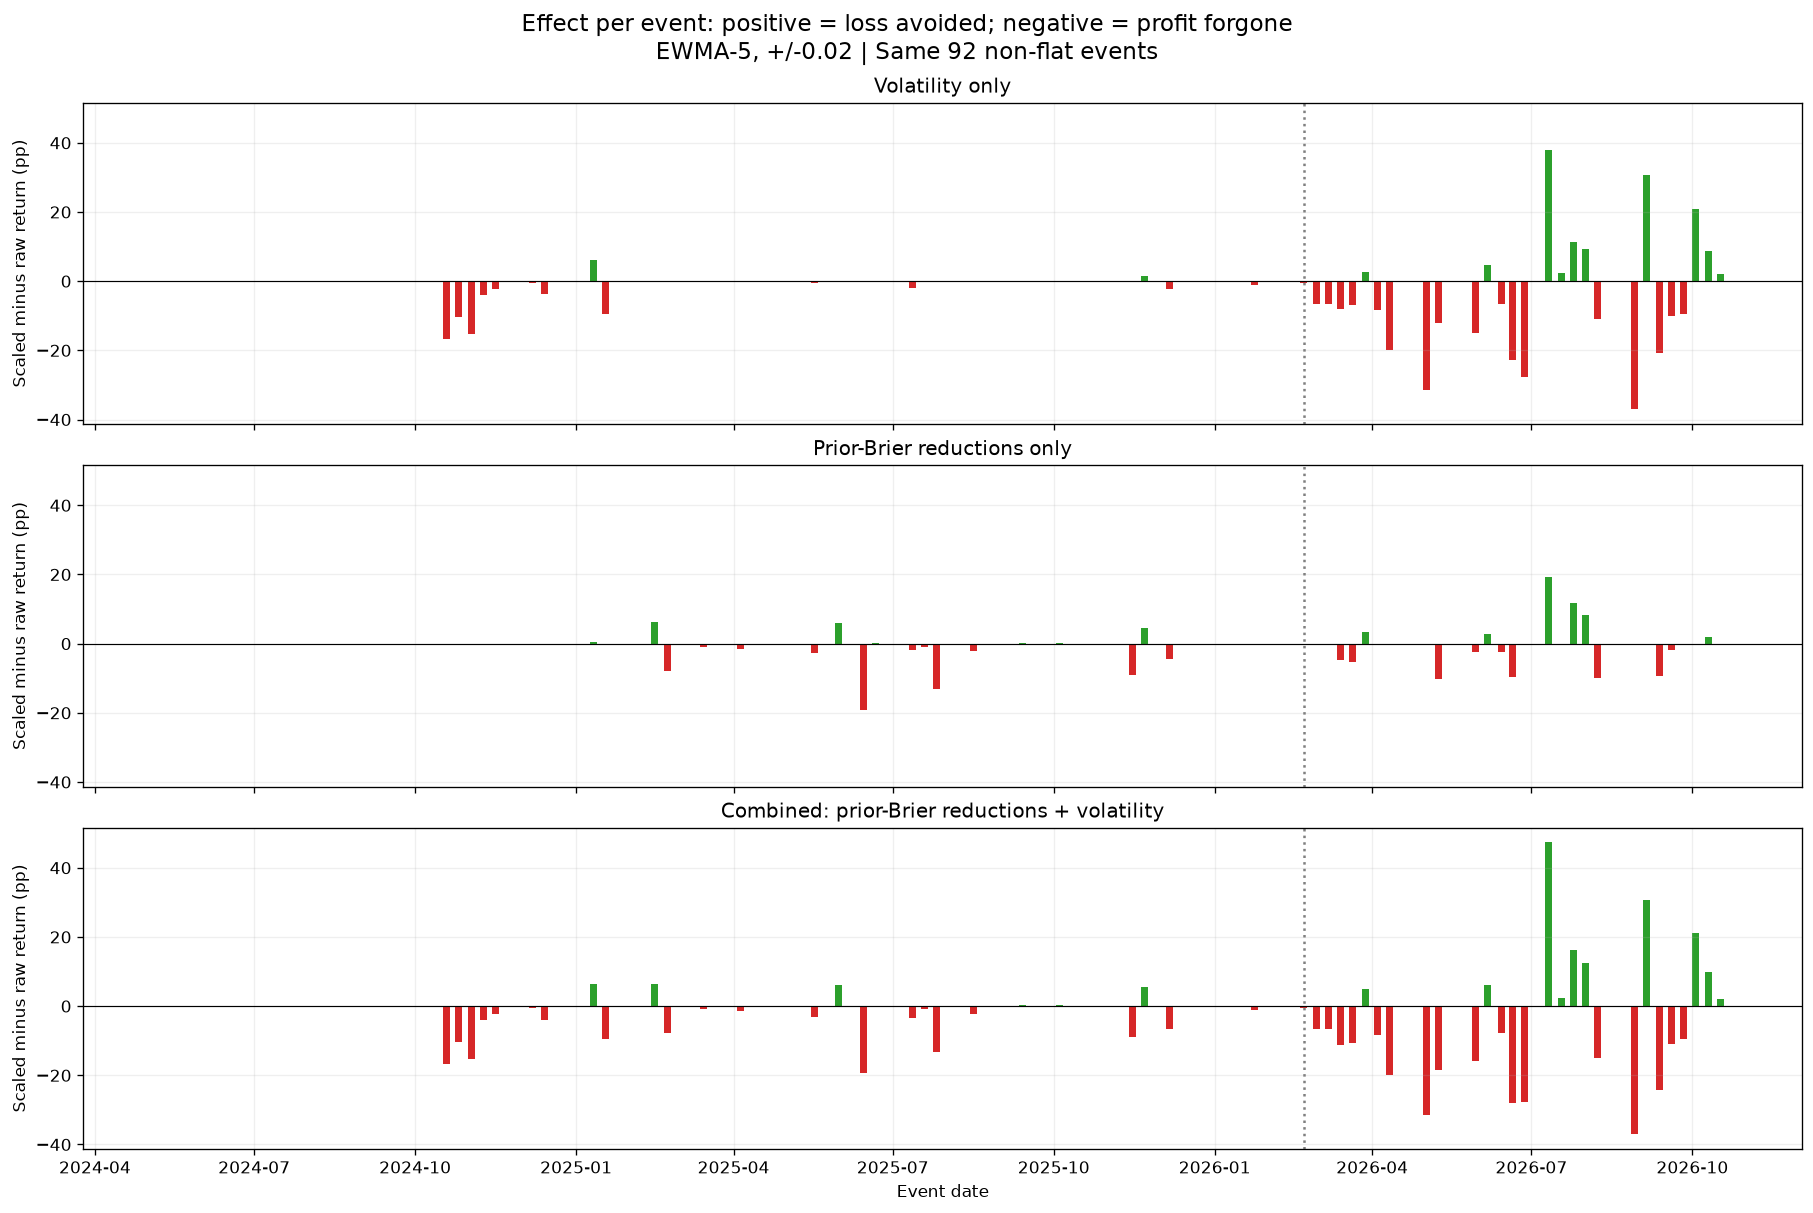

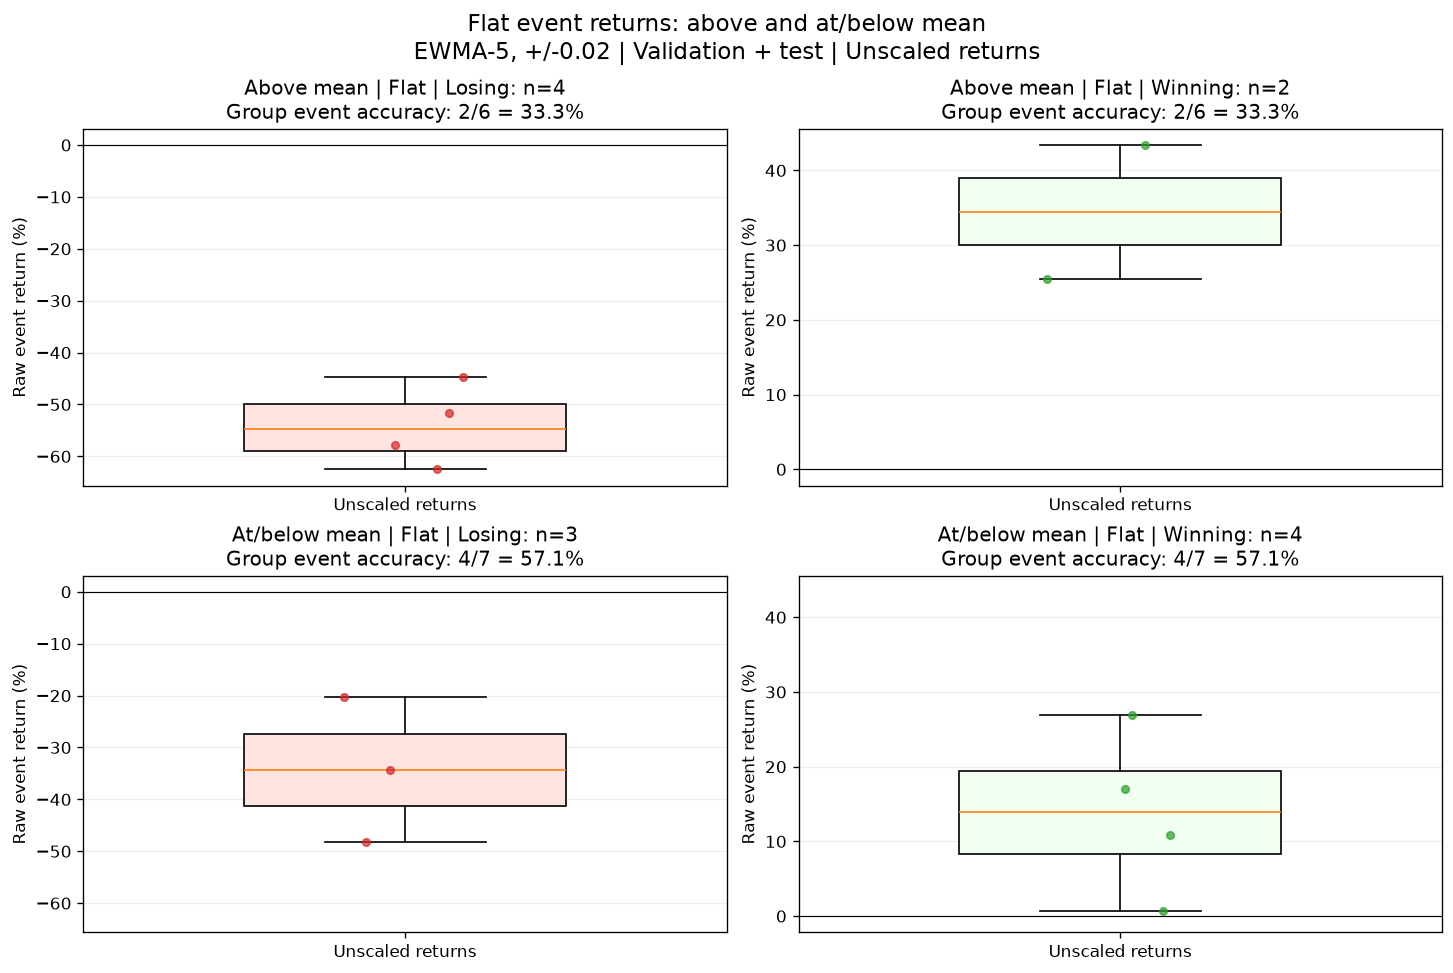

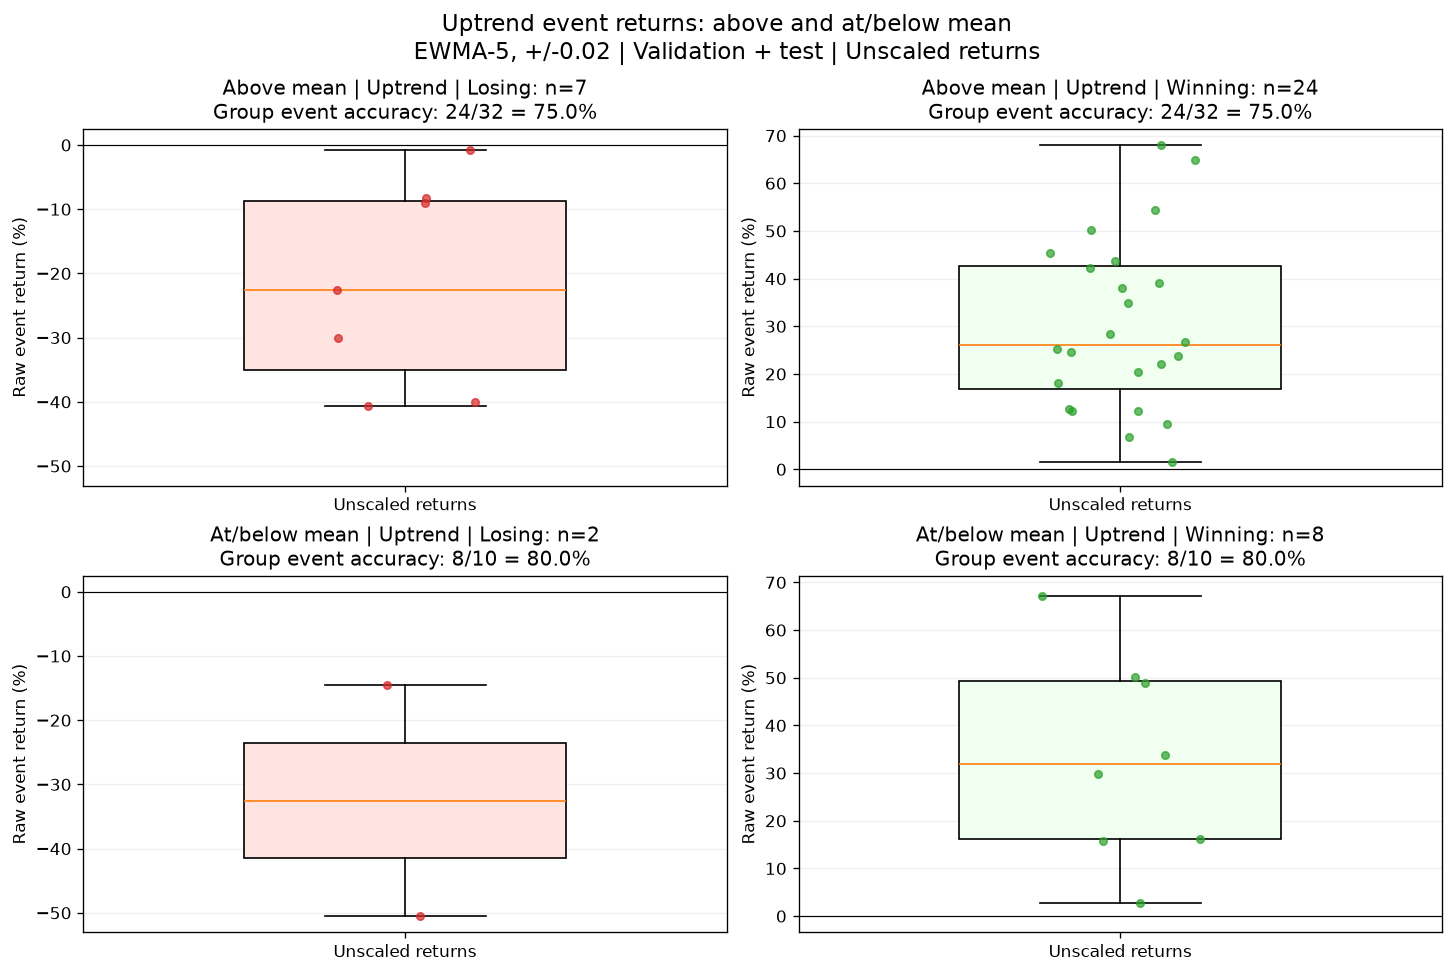

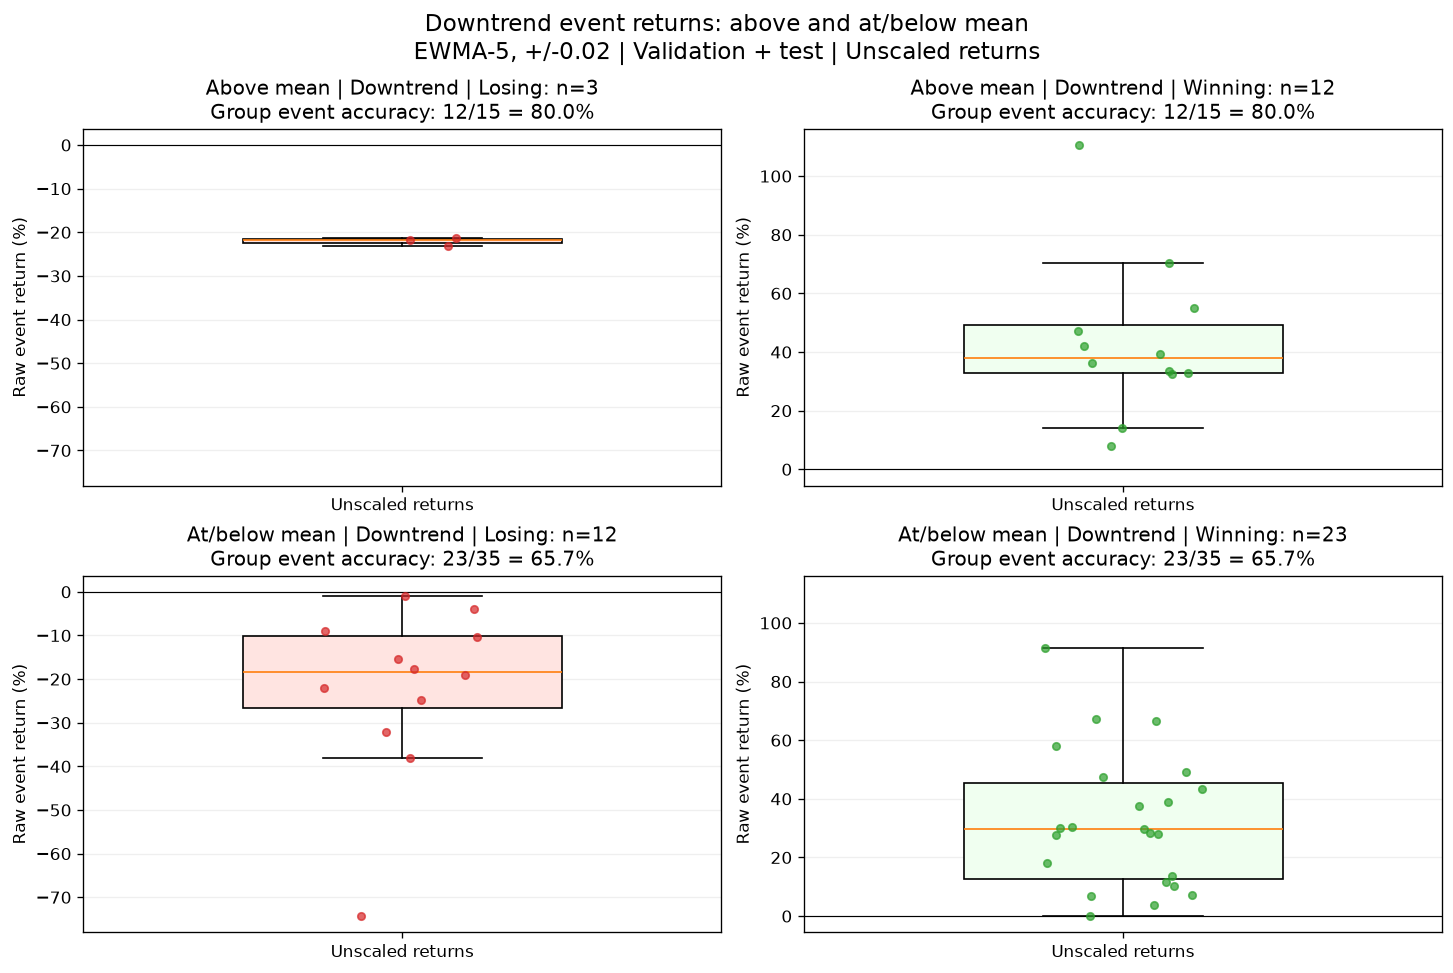

In [4]:
vol_scaling_case = smoothing_results[('EWMA',5,.02)]
vol_scaling_events = vol_scaling_case['events'].sort_index()
vol_scaling_audit = vol_scaling_case['filtered'].sort_index().copy()
records=[]
for date,row in vol_scaling_audit.iterrows():
    prior=vol_scaling_events.loc[vol_scaling_events.index<date]
    target=prior.loc[prior.regime.eq('Above mean') & prior.trend.ne('Flat')].tail(10)
    comparison=prior.loc[prior.regime.eq(row.regime)].tail(10)
    assert (target.index<date).all() and (comparison.index<date).all()
    target_sd=target.return_pct.std(ddof=1) if len(target)==10 else np.nan
    comparison_sd=comparison.return_pct.std(ddof=1) if len(comparison)==10 else np.nan
    ready=np.isfinite(target_sd) and np.isfinite(comparison_sd)
    multiplier=min(1.,target_sd/comparison_sd) if ready and comparison_sd>1e-12 else 1.
    records.append(dict(date=date,target_vol=target_sd,comparison_vol=comparison_sd,
        ready=ready,reconstructed_multiplier=multiplier))
vol_scaling_audit=vol_scaling_audit.join(pd.DataFrame(records).set_index('date'))
np.testing.assert_allclose(vol_scaling_audit.reconstructed_multiplier,vol_scaling_audit.vol_multiplier)
assert vol_scaling_audit.trend.ne('Flat').all() and len(vol_scaling_audit)==92
vol_scaling_audit['return_change_pp']=vol_scaling_audit['Volatility only']-vol_scaling_audit.return_pct
vol_scaling_audit['loss_avoided_pp']=vol_scaling_audit.return_change_pp.clip(lower=0)
vol_scaling_audit['profit_forgone_pp']=-vol_scaling_audit.return_change_pp.clip(upper=0)
vol_scaling_audit['log_growth_change']=np.log1p(vol_scaling_audit['Volatility only']/100)-np.log1p(vol_scaling_audit.return_pct/100)
vol_scaling_audit['reduced']=vol_scaling_audit.vol_multiplier.lt(1-1e-12)
v=vol_scaling_audit
test_marker=vol_scaling_events.index[vol_scaling_events.split.eq('Test')].min()
print('EWMA-5, +/-0.02: fixed above-mean non-flat target; volatility only')
print(pd.DataFrame([dict(strategy=label,**metrics(v[col])) for label,col in
    [('Flat filter only','return_pct'),('Volatility only','Volatility only')]]).to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print(f'Reduced stakes: {v.reduced.sum()} of {len(v)} events; insufficient history: {(~v.ready).sum()}')
print(f'Final scaled/raw wealth ratio: {np.exp(v.log_growth_change.sum()):.4f}')

fig,axes=plt.subplots(3,1,figsize=(15,10),sharex=True,sharey=True,constrained_layout=True)
for ax,column,label in zip(axes,
        ['Volatility only','Prior-Brier reductions','Combined'],
        ['Volatility only','Prior-Brier reductions only','Combined: prior-Brier reductions + volatility']):
    effect=v[column]-v.return_pct
    assert np.isfinite(effect).all()
    ax.bar(v.index,effect,width=4,color=np.where(effect>=0,'tab:green','tab:red'))
    ax.axhline(0,color='black',lw=.7)
    ax.set(title=label,ylabel='Scaled minus raw return (pp)')
    ax.axvline(test_marker,color='gray',ls=':')
    ax.grid(alpha=.2)
axes[-1].set_xlabel('Event date')
fig.suptitle('Effect per event: positive = loss avoided; negative = profit forgone\nEWMA-5, +/-0.02 | Same 92 non-flat events',fontsize=14)
plt.show()

vol_scaling_group_effects=v.groupby(['regime','trend'],sort=True).agg(
    events=('return_pct','size'),reduced_events=('reduced','sum'),
    mean_multiplier=('vol_multiplier','mean'),losses_avoided_pp=('loss_avoided_pp','sum'),
    profits_forgone_pp=('profit_forgone_pp','sum'),log_wealth_effect=('log_growth_change','sum'))
print('Realized scaling effects by pre-event group:')
print(vol_scaling_group_effects.to_string(float_format=lambda x:f'{x:.4f}'))
# Raw filtered returns only; accuracy means strictly positive event return / all retained events.
boxplot_events=vol_scaling_events.copy()
groups=[(regime,trend) for trend in ['Flat','Uptrend','Downtrend'] for regime in ['Above mean','At/below mean']]
accuracy_rows=[]
distribution_rows=[]
for row_idx,(regime,trend) in enumerate(groups):
    if row_idx % 2 == 0:
        fig,axes=plt.subplots(2,2,figsize=(12,8),sharey='col',constrained_layout=True)
    group=boxplot_events.loc[boxplot_events.regime.eq(regime)&boxplot_events.trend.eq(trend)]
    wins=int(group.return_pct.gt(0).sum());losses=int(group.return_pct.lt(0).sum())
    zeros=int(group.return_pct.eq(0).sum());accuracy=100*wins/len(group)
    accuracy_rows.append(dict(regime=regime,trend=trend,events=len(group),winning_events=wins,
        losing_events=losses,zero_return_events=zeros,event_accuracy_pct=accuracy))
    for col_idx,(outcome,mask) in enumerate([('Losing',group.return_pct.lt(0)),('Winning',group.return_pct.gt(0))]):
        part=group.loc[mask];ax=axes[row_idx % 2,col_idx]
        ax.set(title=f'{regime} | {trend} | {outcome}: n={len(part)}\nGroup event accuracy: {wins}/{len(group)} = {accuracy:.1f}%',
               ylabel='Raw event return (%)',xticks=[1],xticklabels=['Unscaled returns'])
        ax.axhline(0,color='black',lw=.7);ax.grid(axis='y',alpha=.2)
        if part.empty:
            ax.text(.5,.5,'No events',transform=ax.transAxes,ha='center');continue
        box=ax.boxplot([part.return_pct.to_numpy()],positions=[1],widths=.4,patch_artist=True,showfliers=False)
        box['boxes'][0].set_facecolor('mistyrose' if outcome=='Losing' else 'honeydew')
        jitter=np.random.default_rng(42+row_idx*2+col_idx).uniform(-.10,.10,len(part))
        ax.scatter(1+jitter,part.return_pct,s=20,color='tab:red' if outcome=='Losing' else 'tab:green',zorder=3,alpha=.7)
        ax.set_xticks([1],['Unscaled returns']);ax.set_xlim(.6,1.4)
        distribution_rows.append(dict(regime=regime,trend=trend,outcome=outcome,events=len(part),
            raw_mean_pct=part.return_pct.mean(),raw_median_pct=part.return_pct.median(),
            raw_p10_pct=part.return_pct.quantile(.10),raw_p90_pct=part.return_pct.quantile(.90)))
    if row_idx % 2 == 1:
        fig.suptitle(f'{trend} event returns: above and at/below mean\nEWMA-5, +/-0.02 | Validation + test | Unscaled returns',fontsize=14)
        plt.show()
vol_scaling_distributions=pd.DataFrame(distribution_rows)
raw_filtered_event_accuracy=pd.DataFrame(accuracy_rows)
print('Event accuracy = positive raw-return events / all events in each group:')
print(raw_filtered_event_accuracy.to_string(index=False,float_format=lambda x:f'{x:.2f}'))
print('Raw return distributions (zero returns excluded from winner/loser panels only):')
print(vol_scaling_distributions.to_string(index=False,float_format=lambda x:f'{x:.3f}'))

# Risk/growth tradeoff by group; log contributions add exactly across groups.
tradeoff_rows=[]
for label,part in [('All retained events',v),*[(f'{a} / {b}',v.loc[v.regime.eq(a)&v.trend.eq(b)]) for a,b in vol_scaling_group_effects.index]]:
    raw=metrics(part.return_pct);scaled=metrics(part['Volatility only'])
    tradeoff_rows.append(dict(group=label,events=len(part),
        raw_geometric_growth_pct=raw['geometric_growth_pct'],scaled_geometric_growth_pct=scaled['geometric_growth_pct'],
        raw_mdd_pct=raw['max_drawdown_pct'],scaled_mdd_pct=scaled['max_drawdown_pct'],
        raw_worst_pct=raw['worst_event_pct'],scaled_worst_pct=scaled['worst_event_pct'],
        losses_avoided_pp=part.loss_avoided_pp.sum(),profits_forgone_pp=part.profit_forgone_pp.sum(),
        log_wealth_effect=part.log_growth_change.sum()))
vol_scaling_tradeoff=pd.DataFrame(tradeoff_rows)
print('Risk/growth tradeoff (group MDD compounds only that group in chronological order):')
print(vol_scaling_tradeoff.to_string(index=False,float_format=lambda x:f'{x:.3f}'))
assert sum(vol_scaling_distributions.events)+boxplot_events.return_pct.eq(0).sum()==len(boxplot_events)
assert raw_filtered_event_accuracy.events.sum()==len(boxplot_events)


## Mean-group return comparison and rolling Brier history

Copied definitions from rolling_brier.ipynb: the return bars include **all 105 validation + test events, including flats**, with original unscaled returns. Above/at-below mean uses prior-event advantage versus its trailing five-calendar-year event-end mean.

The three-panel figure preserves the source plots' different cohorts: advantage uses event-end points and the matching train-only model for train/validation, then the train+validation refit for test. Actual/expected and excess Vegas Brier use the original train+validation prediction cohort and fight ordering, plotted at every fight. All rolling windows contain 100 fights. The horizontal advantage reference is the original training mean, not the five-year grouping threshold.


Original unscaled validation + test returns; flat events included:
               events  mean_return_pct  std_return_pp  geometric_return_per_event_pct
regime                                                                               
Above mean         53          16.6379        35.6613                         10.1369
At/below mean      52          12.1051        33.8612                          6.0914


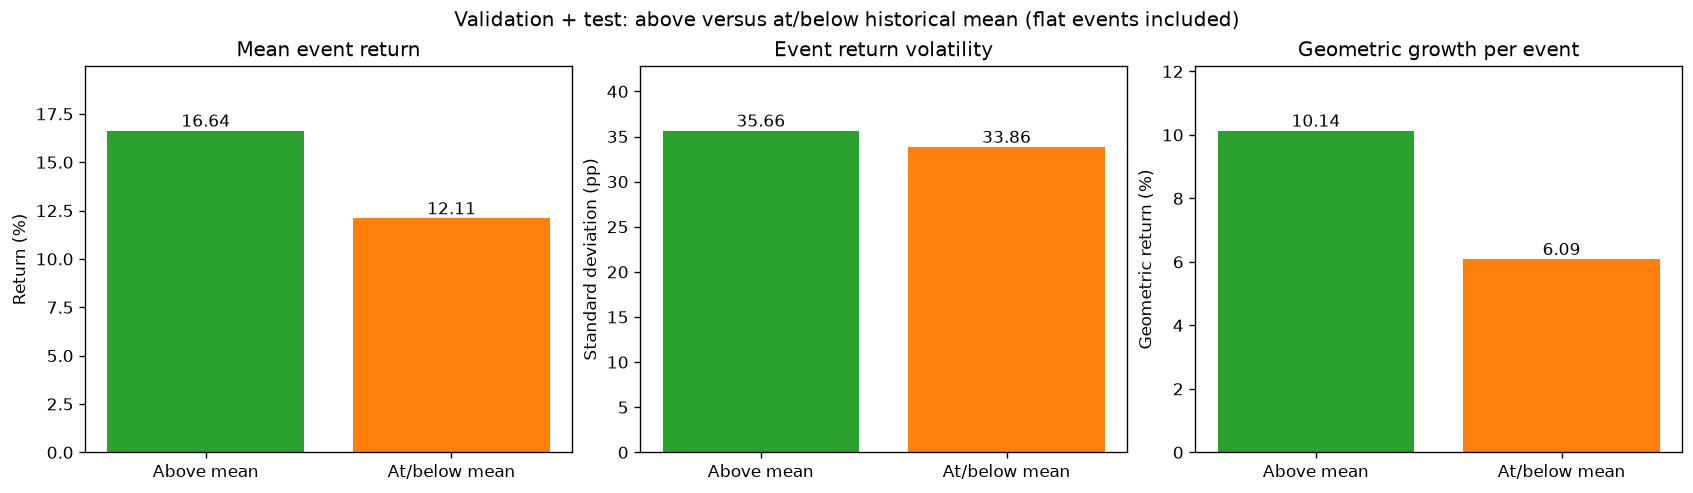

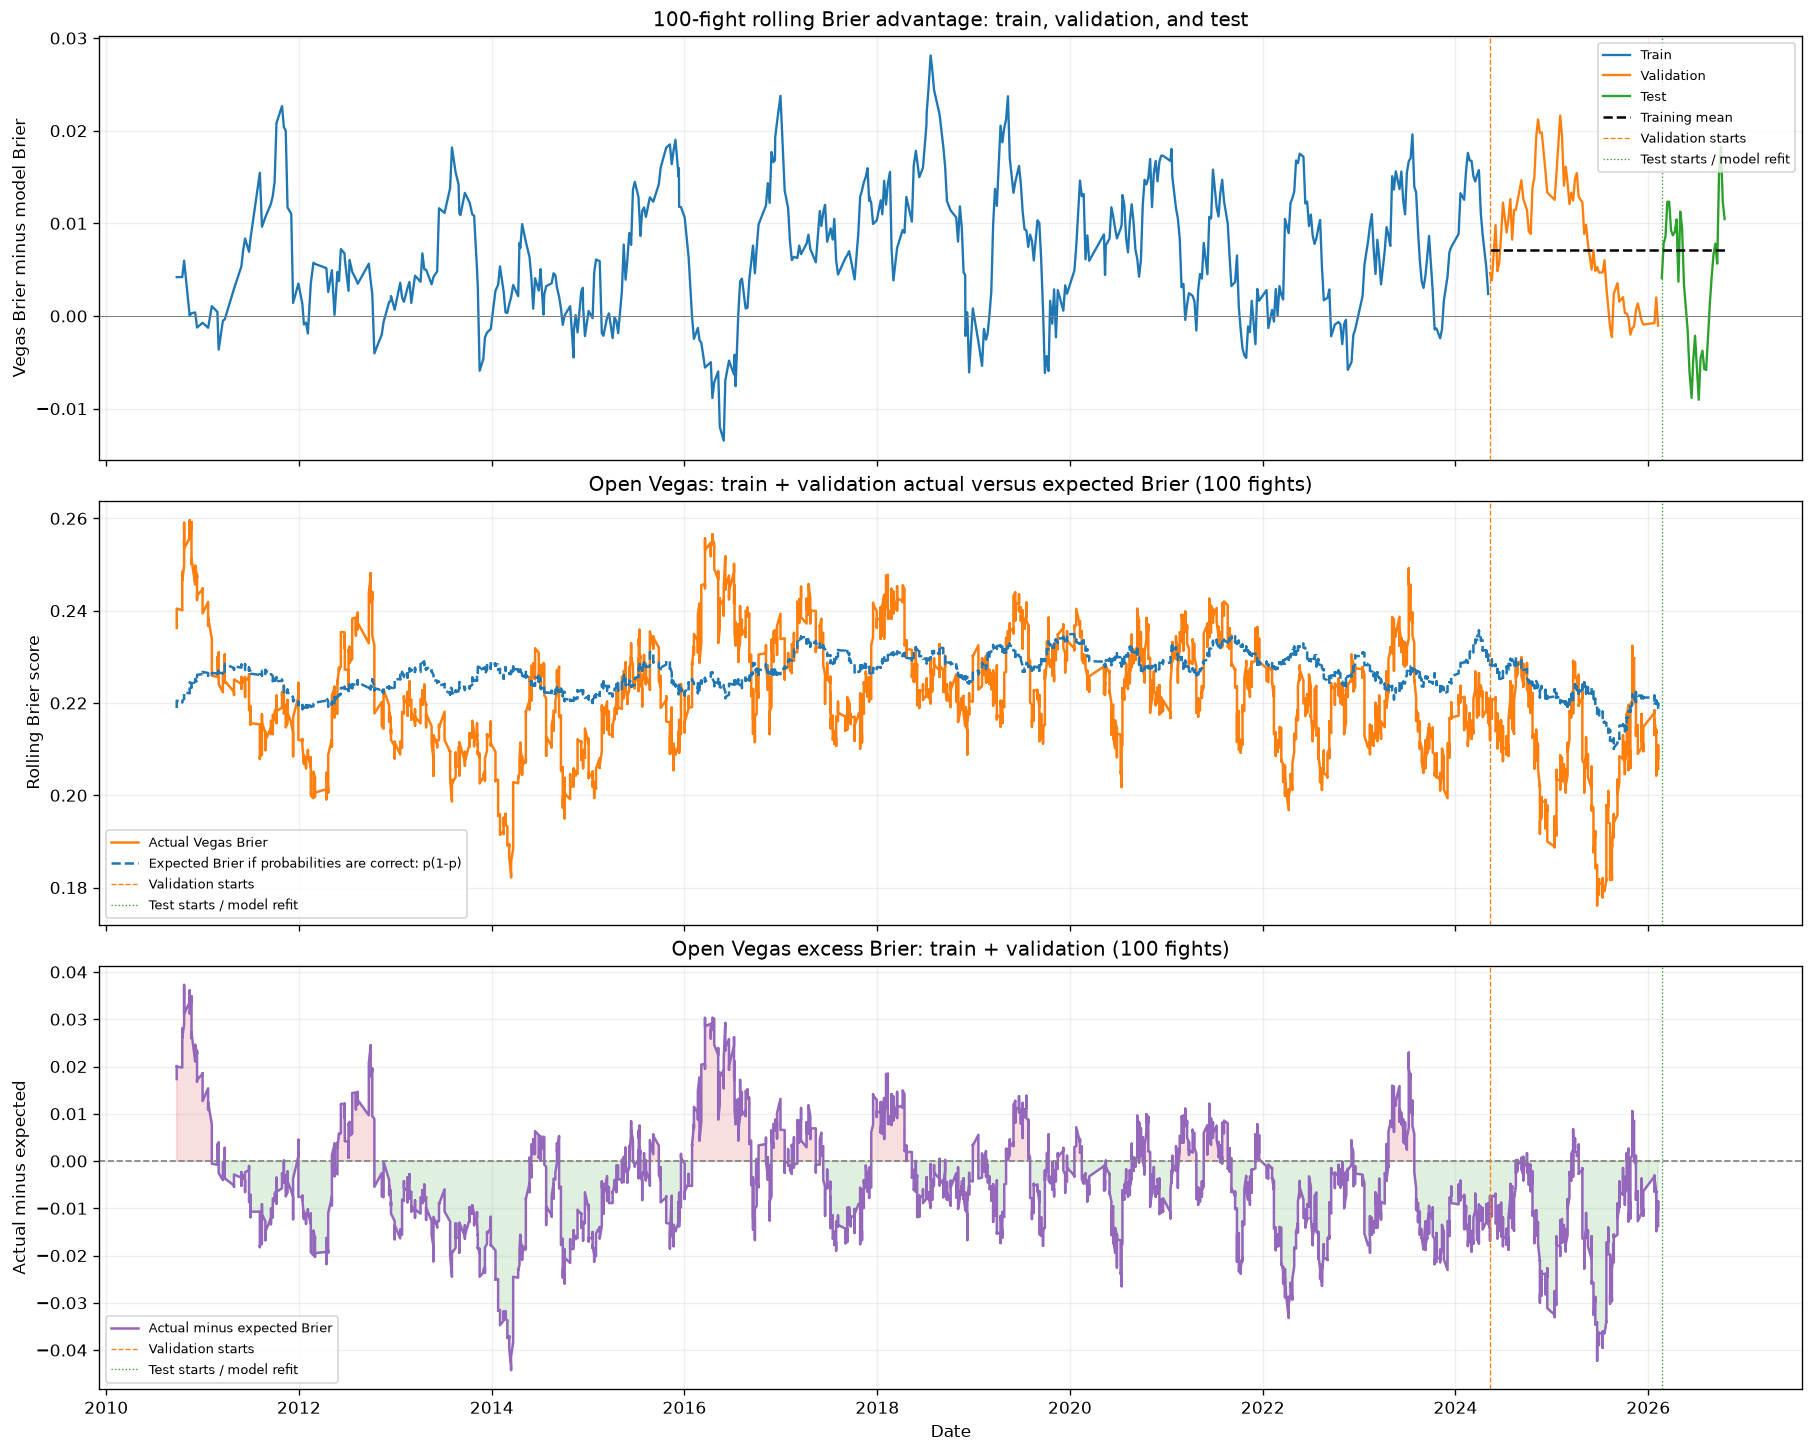

In [5]:
import matplotlib.dates as mdates

copied_case=smoothing_results[('EWMA',5,.02)]
copied_events=copied_case['events']
copied_mean_summary=pd.DataFrame([
    dict(regime=regime,events=len(part),mean_return_pct=part.return_pct.mean(),
         std_return_pp=part.return_pct.std(ddof=1),
         geometric_return_per_event_pct=100*np.expm1(np.log1p(part.return_pct/100).mean()))
    for regime,part in copied_events.groupby('regime')
]).set_index('regime').reindex(['Above mean','At/below mean'])
assert copied_mean_summary.events.sum()==105
print('Original unscaled validation + test returns; flat events included:')
print(copied_mean_summary.to_string(float_format=lambda x:f'{x:.4f}'))
fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
for ax,col,title,ylabel in zip(axes,
    ['mean_return_pct','std_return_pp','geometric_return_per_event_pct'],
    ['Mean event return','Event return volatility','Geometric growth per event'],
    ['Return (%)','Standard deviation (pp)','Geometric return (%)']):
    values=copied_mean_summary[col]
    bars=ax.bar(values.index,values,color=['tab:green','tab:orange'])
    ax.bar_label(bars,fmt='%.2f');ax.axhline(0,color='gray',lw=.6)
    ax.set(title=title,ylabel=ylabel);ax.margins(y=.2)
fig.suptitle('Validation + test: above versus at/below historical mean (flat events included)')
plt.show()

# Match the source Vegas plot: trainval prediction cohort and original within-date ordering.
vegas_history=pd.read_csv(PREDICTIONS/'trainval/open/inference/train_with_open.csv')
vegas_history['date']=pd.to_datetime(vegas_history.date)
order=['date']+(['bout_position'] if 'bout_position' in vegas_history else [])+['fighter_red','fighter_blue']
vegas_history=score_fights(vegas_history.sort_values(order,kind='stable').reset_index(drop=True),'open')
for column in ['vegas_actual','vegas_expected','excess']:
    vegas_history['rolling_'+column]=vegas_history[column].rolling(100,min_periods=100).mean()
np.testing.assert_allclose(vegas_history.rolling_excess,
    vegas_history.rolling_vegas_actual-vegas_history.rolling_vegas_expected,atol=1e-14,equal_nan=True)
train_end=pd.to_datetime(pd.read_csv(PREDICTIONS/'train/open/inference/train_with_open.csv').date).max()
validation_start=copied_events.index[copied_events.split.eq('Validation')].min()
test_start=copied_events.index[copied_events.split.eq('Test')].min()
training_mean=copied_case['histories']['Validation'].loc[
    copied_case['histories']['Validation'].date.le(train_end),'rolling_advantage'].mean()
fig,axes=plt.subplots(3,1,figsize=(15,12),sharex=True,constrained_layout=True)
for stage,color in [('Train','tab:blue'),('Validation','tab:orange'),('Test','tab:green')]:
    history=copied_case['histories']['Test' if stage=='Test' else 'Validation']
    endpoints=history.groupby('date').rolling_advantage.last()
    points=endpoints.loc[endpoints.index<=train_end] if stage=='Train' else endpoints.reindex(
        copied_events.index[copied_events.split.eq(stage)])
    axes[0].plot(points.index,points,color=color,label=stage,lw=1.4)
axes[0].hlines(training_mean,validation_start,copied_events.index.max(),colors='black',linestyles='--',label='Training mean')
axes[0].axhline(0,color='gray',lw=.6)
axes[0].set(title='100-fight rolling Brier advantage: train, validation, and test',ylabel='Vegas Brier minus model Brier')
axes[1].plot(vegas_history.date,vegas_history.rolling_vegas_actual,color='tab:orange',label='Actual Vegas Brier')
axes[1].plot(vegas_history.date,vegas_history.rolling_vegas_expected,color='tab:blue',ls='--',label='Expected Brier if probabilities are correct: p(1-p)')
axes[1].set(title='Open Vegas: train + validation actual versus expected Brier (100 fights)',ylabel='Rolling Brier score')
axes[2].plot(vegas_history.date,vegas_history.rolling_excess,color='tab:purple',label='Actual minus expected Brier')
axes[2].fill_between(vegas_history.date,0,vegas_history.rolling_excess,where=vegas_history.rolling_excess.ge(0),color='tab:red',alpha=.15)
axes[2].fill_between(vegas_history.date,0,vegas_history.rolling_excess,where=vegas_history.rolling_excess.lt(0),color='tab:green',alpha=.15)
axes[2].axhline(0,color='gray',ls='--',lw=1)
axes[2].set(title='Open Vegas excess Brier: train + validation (100 fights)',ylabel='Actual minus expected',xlabel='Date')
for ax in axes:
    ax.axvline(validation_start,color='tab:orange',ls='--',lw=.8,label='Validation starts')
    ax.axvline(test_start,color='tab:green',ls=':',lw=.8,label='Test starts / model refit')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
locator=mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(locator);axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.show()


## Event-only Brier correlations versus percent returns

Copied comparisons from rolling_brier.ipynb using the **train-only opening inference model and all 72 validation event returns**, including flat events and both singles/parlays. Window 0 means the event's average across eligible fights, not a zero-length average. Training history supplies the previous event for the first validation event.

Panels: previous-event actual Vegas Brier; previous-event Vegas minus model Brier; same-event Vegas minus model Brier. Prior predictors exclude current outcomes. The same-event panel shares outcomes with returns and is descriptive, not a pre-event signal. No rolling averaging or stake scaling is applied.

Pearson 95% confidence intervals use 2,000 paired moving-block bootstrap resamples, with blocks of 5 chronological events (seed 42), matching the source notebook method. Intervals are approximate and descriptive.


                              comparison  events  pearson_r  ci_low  ci_high  spearman_r
Prior actual Vegas Brier: 0-fight window      72     0.1912  0.0033   0.4048      0.1974
       Prior-event advantage: event only      72    -0.1379 -0.3760   0.1084     -0.2001
        Same-event advantage: event only      72     0.7286  0.5304   0.8245      0.6621


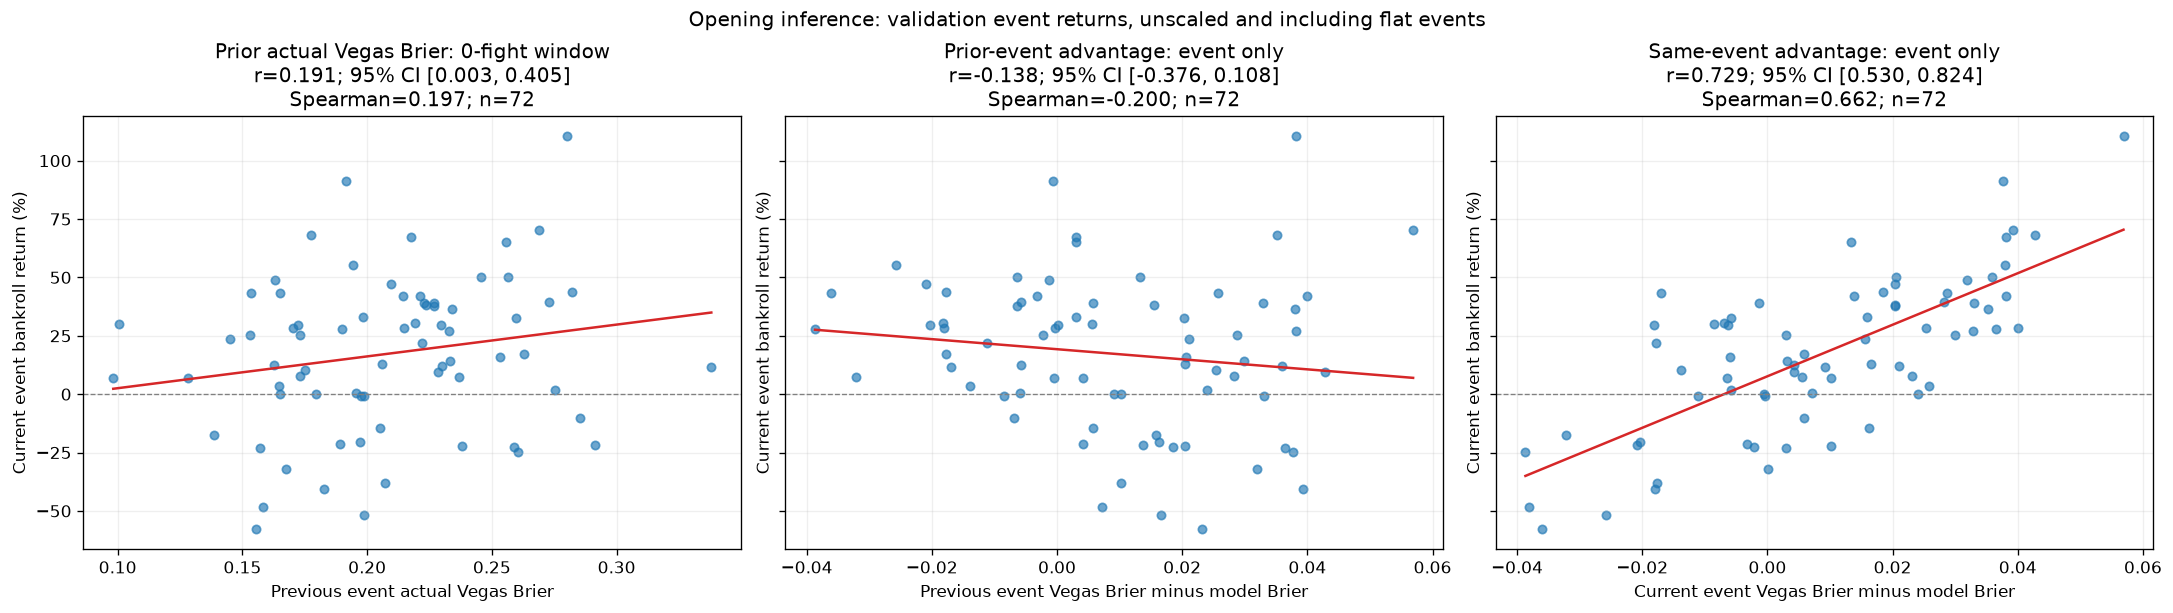

In [6]:
from scipy.stats import pearsonr, spearmanr

def event_only_pearson_ci(x,y):
    rng=np.random.default_rng(42)
    x=np.asarray(x,float);y=np.asarray(y,float)
    count=len(x);block=min(5,count);draws=2000
    starts=rng.integers(0,count-block+1,size=(draws,int(np.ceil(count/block))))
    ids=(starts[:,:,None]+np.arange(block)).reshape(draws,-1)[:,:count]
    a=x[ids];b=y[ids]
    a-=a.mean(axis=1,keepdims=True);b-=b.mean(axis=1,keepdims=True)
    denominator=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    cor=np.divide((a*b).sum(axis=1),denominator,out=np.full(draws,np.nan),where=denominator>0)
    return np.quantile(cor[np.isfinite(cor)],[.025,.975])

correlation_case=smoothing_results[('EWMA',5,.02)]
correlation_history=correlation_case['histories']['Validation']
correlation_returns=correlation_case['events'].loc[lambda x:x.split.eq('Validation'),'return_pct']
event_scores=correlation_history.groupby('date')[['vegas_actual','advantage']].mean()
event_score_dates=pd.Series(event_scores.index,index=event_scores.index)
assert (event_score_dates.shift(1).reindex(correlation_returns.index)<correlation_returns.index).all()
correlation_specs=[
    ('Prior actual Vegas Brier: 0-fight window',event_scores.vegas_actual.shift(1),'Previous event actual Vegas Brier'),
    ('Prior-event advantage: event only',event_scores.advantage.shift(1),'Previous event Vegas Brier minus model Brier'),
    ('Same-event advantage: event only',event_scores.advantage,'Current event Vegas Brier minus model Brier')]
event_only_correlation_pairs={};event_only_correlation_rows=[]
fig,axes=plt.subplots(1,3,figsize=(18,5),sharey=True,constrained_layout=True)
for ax,(label,predictor,xlabel) in zip(axes,correlation_specs):
    sample=pd.DataFrame({'brier':predictor.reindex(correlation_returns.index),'return_pct':correlation_returns}).dropna()
    assert len(sample)==72
    event_only_correlation_pairs[label]=sample
    r=pearsonr(sample.brier,sample.return_pct).statistic
    rho=spearmanr(sample.brier,sample.return_pct).statistic
    lo,hi=event_only_pearson_ci(sample.brier,sample.return_pct)
    event_only_correlation_rows.append(dict(comparison=label,events=len(sample),pearson_r=r,ci_low=lo,ci_high=hi,spearman_r=rho))
    ax.scatter(sample.brier,sample.return_pct,alpha=.65,s=25)
    slope,intercept=np.polyfit(sample.brier,sample.return_pct,1)
    grid=np.linspace(sample.brier.min(),sample.brier.max(),100)
    ax.plot(grid,intercept+slope*grid,color='tab:red')
    ax.axhline(0,color='gray',ls='--',lw=.8)
    ax.set(title=f'{label}\nr={r:.3f}; 95% CI [{lo:.3f}, {hi:.3f}]\nSpearman={rho:.3f}; n={len(sample)}',xlabel=xlabel,ylabel='Current event bankroll return (%)')
    ax.grid(alpha=.2)
fig.suptitle('Opening inference: validation event returns, unscaled and including flat events')
plt.show()
event_only_correlations=pd.DataFrame(event_only_correlation_rows)
print(event_only_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))


In [5]:
428 - (428*0.45)

235.4

## Bankroll from 500: validation and test separately (EWMA-5, +/-0.02)

Each period starts at 500 and compounds event percentage returns: bankroll = 500 * product(1 + return/100). Raw unfiltered includes every event. Flat-filter-only and all three scaling variants skip flat events (zero return on those dates). Volatility uses the existing fixed above-mean non-flat 10-event target. Prior-Brier scaling is reduction-only; combined multiplies the two reductions. Scalers use historical information strictly before each event and carry validation history into test; only displayed bankroll resets. Test uses its saved train+validation-refitted opening model. These are proportional rescalings of saved strategy returns, not new bet-selection simulations.


    period         strategy  calendar_events  retained_events  starting_bankroll  ending_bankroll   net_profit  cumulative_return_pct
Validation   Raw unfiltered               72               72             500.00     1,867,346.06 1,866,846.06             373,369.21
Validation Remove flat only               72               63             500.00     8,274,198.67 8,273,698.67           1,654,739.73
Validation  Volatility only               72               63             500.00     5,497,744.65 5,497,244.65           1,099,448.93
Validation Prior-Brier only               72               63             500.00     6,409,822.89 6,409,322.89           1,281,864.58
Validation         Combined               72               63             500.00     4,261,274.16 4,260,774.16             852,154.83
      Test   Raw unfiltered               33               33             500.00           483.63       -16.37                  -3.27
      Test Remove flat only               33               29 

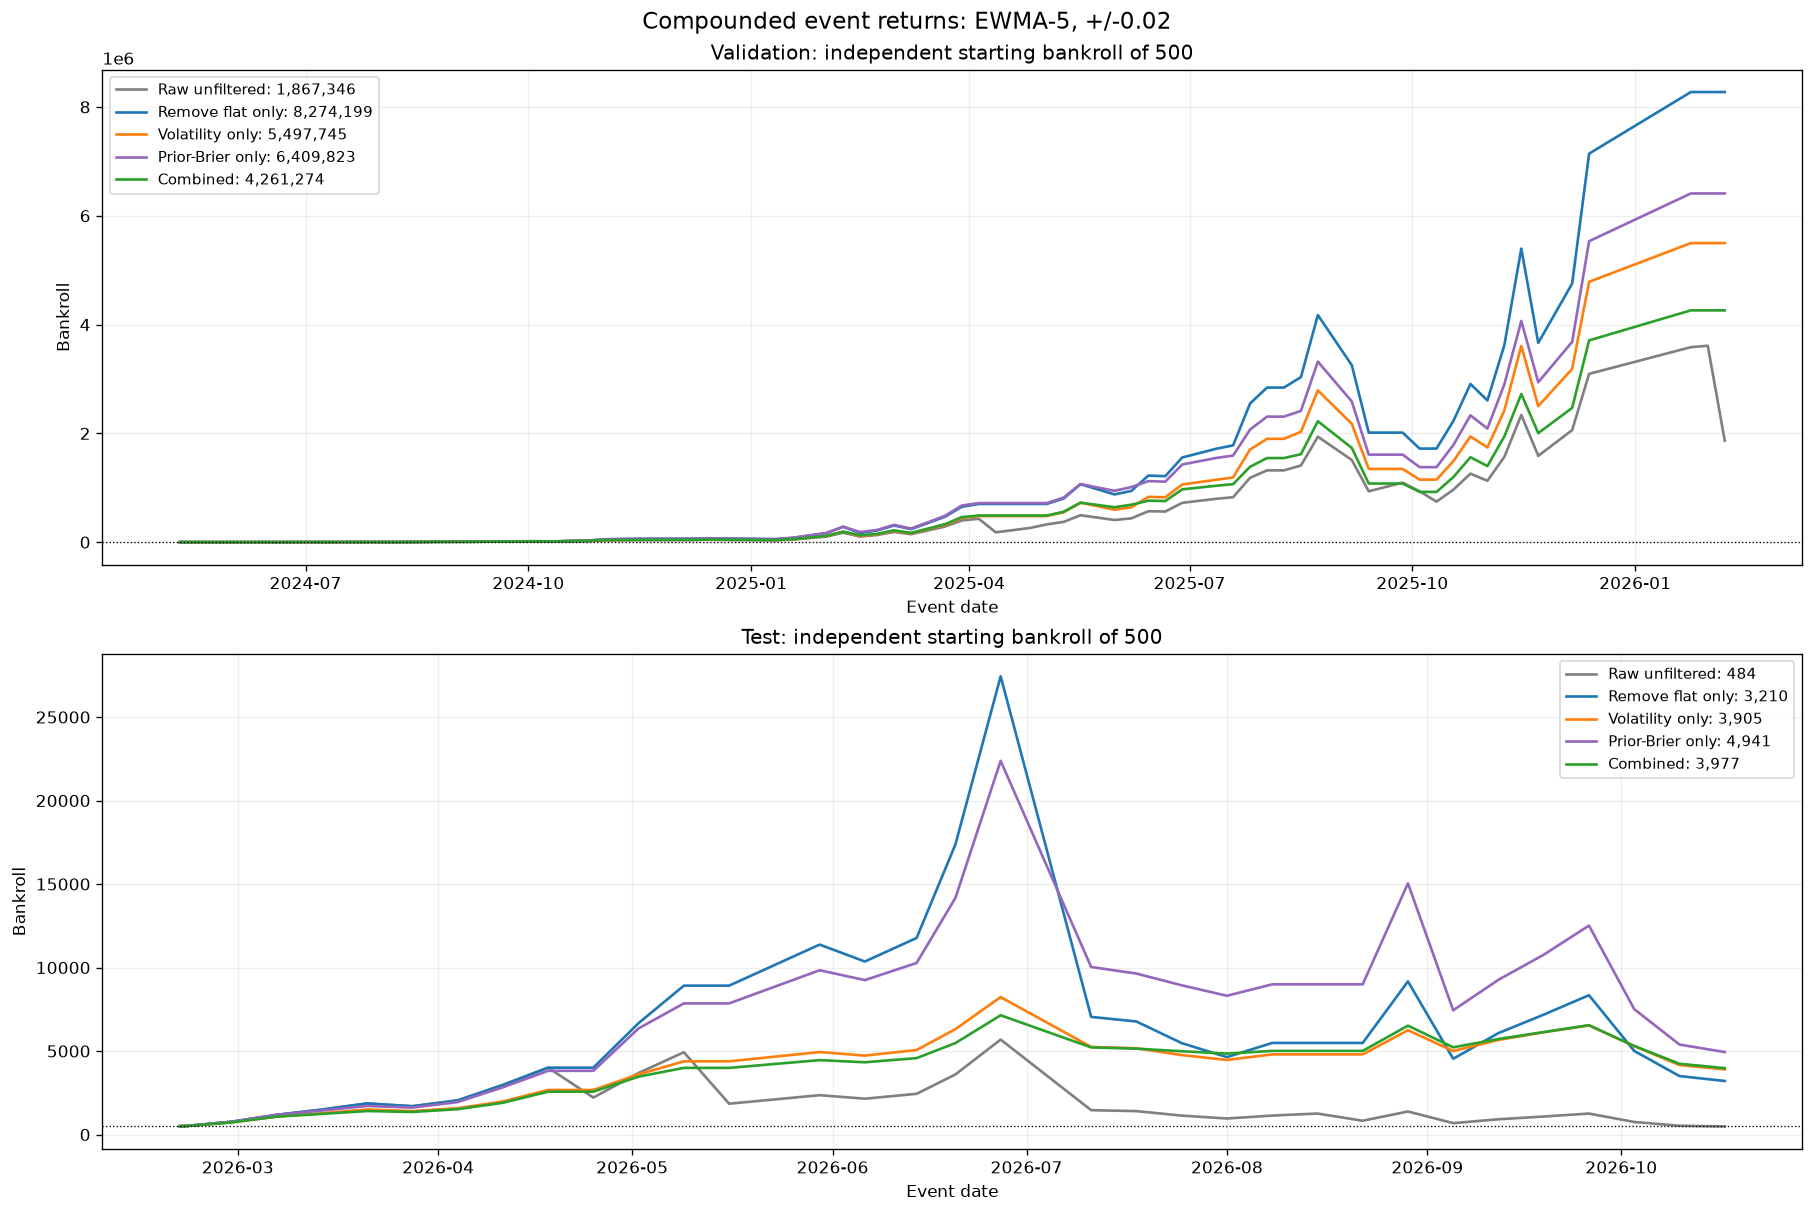

In [7]:
bankroll_case=smoothing_results[('EWMA',5,.02)]
bankroll_all=bankroll_case['events'].sort_index()
bankroll_active=bankroll_case['filtered'].sort_index()
bankroll_variants={
    'Raw unfiltered':bankroll_all.return_pct,
    'Remove flat only':bankroll_active.return_pct.reindex(bankroll_all.index,fill_value=0),
    'Volatility only':bankroll_active['Volatility only'].reindex(bankroll_all.index,fill_value=0),
    'Prior-Brier only':bankroll_active['Prior-Brier reductions'].reindex(bankroll_all.index,fill_value=0),
    'Combined':bankroll_active['Combined'].reindex(bankroll_all.index,fill_value=0),
}
bankroll_paths={};bankroll_summary_rows=[]
fig,axes=plt.subplots(2,1,figsize=(15,10),constrained_layout=True)
colors=['gray','tab:blue','tab:orange','tab:purple','tab:green']
for ax,period in zip(axes,['Validation','Test']):
    dates=bankroll_all.index[bankroll_all.split.eq(period)]
    start_date=dates.min()-pd.Timedelta(days=1)
    for (label,series),color in zip(bankroll_variants.items(),colors):
        returns=series.reindex(dates)
        assert returns.notna().all() and returns.gt(-100).all()
        if label!='Raw unfiltered':
            assert returns.loc[~bankroll_all.loc[dates,'opening_keep']].eq(0).all()
        path=pd.Series(np.r_[500.,500.*(1+returns/100).cumprod().to_numpy()],
                       index=pd.DatetimeIndex([start_date,*dates]))
        bankroll_paths[(period,label)]=path
        assert path.iloc[0]==500.
        ax.plot(path.index,path,color=color,label=f'{label}: {path.iloc[-1]:,.0f}',lw=1.6)
        bankroll_summary_rows.append(dict(period=period,strategy=label,
            calendar_events=len(dates),retained_events=len(dates) if label=='Raw unfiltered' else int(bankroll_all.loc[dates,'opening_keep'].sum()),
            starting_bankroll=500.,ending_bankroll=path.iloc[-1],net_profit=path.iloc[-1]-500.,
            cumulative_return_pct=100*(path.iloc[-1]/500.-1)))
    ax.axhline(500,color='black',ls=':',lw=.8)
    ax.set(title=f'{period}: independent starting bankroll of 500',ylabel='Bankroll',xlabel='Event date')
    ax.legend(fontsize=9);ax.grid(alpha=.2)
fig.suptitle('Compounded event returns: EWMA-5, +/-0.02',fontsize=14)
plt.show()
bankroll_period_summary=pd.DataFrame(bankroll_summary_rows)
print(bankroll_period_summary.to_string(index=False,float_format=lambda x:f'{x:,.2f}'))
